**[🏠 Course Home](00_START_HERE.ipynb)** | **📖 [Conceptual](../conceptual/12_bayesian_regression_and_glms.ipynb)** | **🐍 [Python](../python/12_bayesian_regression_and_glms.ipynb)** | **⬅️ [Prev: Ch 11: Two-Group t-Test (Freq vs. Bayes)](11_t_test_frequentist_vs_bayesian.ipynb)** | **➡️ [Next: Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)**

*🧭 Part III: Applied Modeling, Regression, Hierarchy & Model Comparison — Chapter 12 of 22*

---

# Chapter 12: Bayesian Linear Regression, Poisson-Gamma Counts & GLMs (R Track)
### *The Moving Bell Curve, Exact Rate Conjugacy, Centered Geometry,*
### *and Two Uncertainty Ribbons*

---

## 🧭 The Learning Progression
* **Previous**: Comparing discrete group means (A/B testing,
  hierarchical models).
* **👉 Chapter 12 (You are here)**: Modeling continuous functional relationships
  $\mu(x) = \alpha + \beta x$, event count rates with Poisson-Gamma, and
  bounded probabilities with Logistic GLMs.
* **Next**: Model comparison, cross-validation, and information criteria
  (WAIC, LOO-CV).

---

## Table of Contents
1. **Part 1: From Static Means to Conditional Models**
   $\mu(x) = \alpha + \beta x$
2. **Part 2: The Third Conjugate Pillar — Poisson-Gamma Event Rates**
3. **Part 3: Bayesian Linear Regression & The Geometry of Centering**
4. **Part 4: Generalized Linear Models (GLMs) & Bayesian Logistic Regression**
5. **Part 5: 3-Tier Scaffolding Exercises**


## Part 1: From Static Group Means to Conditional Models

In earlier sheets, we estimated the static mean of a single population
or compared two discrete groups ($A$ vs. $B$).
In production engineering, however, physical metrics do not live in
isolated categorical buckets: response latency varies continuously with
incoming request load (QPS), and failure rates vary continuously with
operating temperature.

### 🔦 The Physical Analogy: The Moving Spotlight on Rails
Imagine an automated gantry crane sliding along an overhead rail above
a production conveyor:
* **The Rail ($\mu(x) = \alpha + \beta x$)**: The expected response changes
  linearly with external load $x$.
* **The Spotlight Carriage**: As load $x$ shifts, the carriage slides along
  the rail, positioning the center of the bell curve at height $\mu(x)$.
* **The Scatter Beam ($\sigma$)**: Individual measurements do not land
  exactly on the rail; thread scheduling, network jitter, and cache
  contention disperse requests around $\mu(x)$ according to Gaussian
  spread $\mathcal{N}(0, \sigma^2)$.


## Part 2: The Third Conjugate Pillar — Poisson-Gamma for Event Rates

Before fitting continuous regression lines, we master the third pillar
of exact analytical conjugacy:
1. **Beta-Binomial**: Discrete binary trials ($p \in [0, 1]$).
2. **Normal-Normal**: Continuous real-valued measurements ($y \in \mathbb{R}$).
3. **Poisson-Gamma**: Event counts over continuous exposure
   ($k \sim \text{Poisson}(\lambda T)$ with $\lambda > 0$).

### Exact Analytical Updating
For rare events occurring at rate $\lambda$ over exposure duration $T$:
$$P(k \mid \lambda, T) = \frac{(\lambda T)^k e^{-\lambda T}}{k!}
\propto \lambda^k e^{-\lambda T}$$

With conjugate prior $\lambda \sim \text{Gamma}(\alpha_0, \beta_0)$ where
$\mathbb{E}[\lambda] = \alpha_0 / \beta_0$:
$$\alpha_{\text{post}} = \alpha_0 + k, \qquad
\beta_{\text{post}} = \beta_0 + T$$

$$\mathbb{E}[\lambda \mid k, T] = \frac{\alpha_0 + k}{\beta_0 + T}, \qquad
\text{Var}(\lambda \mid k, T) = \frac{\alpha_0 + k}{(\beta_0 + T)^2}$$


In [1]:
# --- Step 1: Exact Poisson-Gamma Updating for Incident Rates ---
# Prior: Gamma(alpha_0, beta_0)
# alpha_0 = 2 pseudo-events, beta_0 = 5 pseudo-hours
alpha_0 <- 2.0
beta_0 <- 5.0
prior_mean <- alpha_0 / beta_0
prior_std <- sqrt(alpha_0) / beta_0

# Observation: k = 4 incidents over T = 10 hours
k_obs <- 4.0
T_obs <- 10.0

# Exact conjugate posterior parameters
alpha_post <- alpha_0 + k_obs
beta_post <- beta_0 + T_obs
post_mean <- alpha_post / beta_post
post_std <- sqrt(alpha_post) / beta_post
ci_95 <- qgamma(c(0.025, 0.975), shape = alpha_post, rate = beta_post)

cat(sprintf("Prior:     Gamma(alpha=%.1f, beta=%.1f)\n", alpha_0, beta_0))
cat(sprintf("Prior Mean: %.4f events/hr, Std: %.4f\n", prior_mean, prior_std))
cat(sprintf("Observed:  k = %.0f events over T = %.1f hours\n", k_obs, T_obs))
cat(sprintf("Posterior: Gamma(alpha=%.1f, beta=%.1f)\n", alpha_post, beta_post))
cat(sprintf("Post Mean:  %.4f events/hr, Std: %.4f\n", post_mean, post_std))
cat(sprintf("95%% Equal-Tailed Credible Interval: [%.4f, %.4f]\n",
            ci_95[1], ci_95[2]))


Prior:     Gamma(alpha=2.0, beta=5.0)


Prior Mean: 0.4000 events/hr, Std: 0.2828


Observed:  k = 4 events over T = 10.0 hours


Posterior: Gamma(alpha=6.0, beta=15.0)


Post Mean:  0.4000 events/hr, Std: 0.1633


95% Equal-Tailed Credible Interval: [0.1468, 0.7779]


### 🔍 Visual Decoding: Rate Uncertainty Shrinks with Exposure Duration $T$

Notice how information accumulates in the Poisson-Gamma model:
* The posterior mean $\mathbb{E}[\lambda] = \frac{\alpha_0 + k}{\beta_0 + T}$ is
  a weighted balance between prior rate $\alpha_0/\beta_0$ and empirical
  sample rate $k/T$.
* The posterior variance
  $\text{Var}(\lambda) = \alpha_{\text{post}} / \beta_{\text{post}}^2$
  $\approx \lambda / T$
  contracts strictly as $1/T$.
* As exposure duration $T \to \infty$, the posterior distribution converges
  to a sharp spike centered on the ground-truth rate $\lambda_{\text{true}}$.


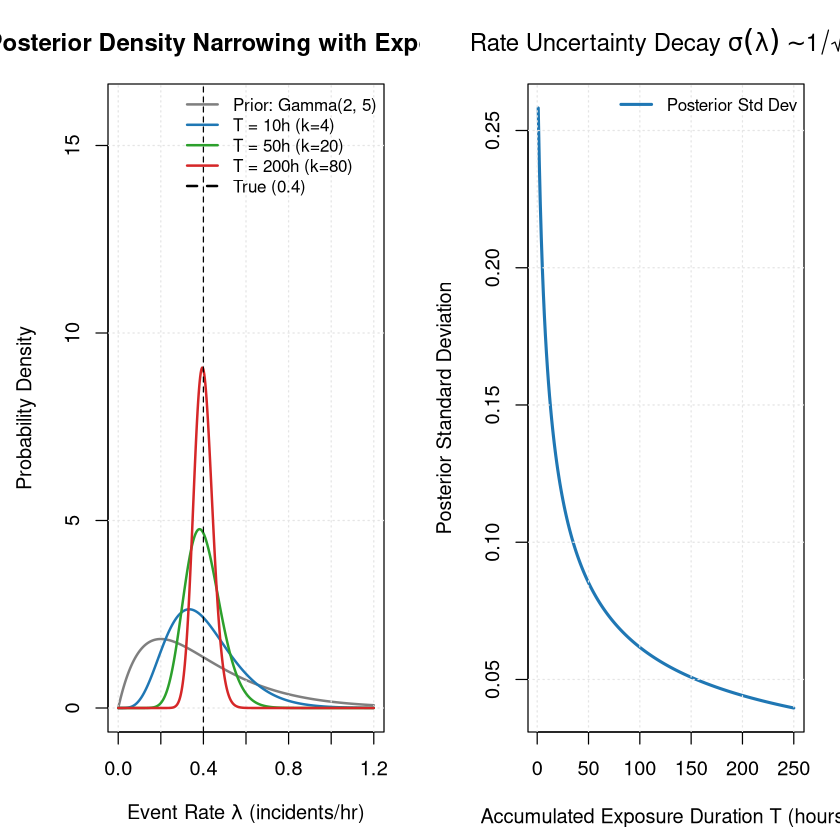

In [2]:
# --- Step 2: Visualizing Rate Contraction with Exposure ---
rate_grid <- seq(0.0, 1.2, length.out = 500)
par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3.5, 1.5))

# Panel 1: Density curves across exposure scenarios
plot(rate_grid, dgamma(rate_grid, shape = 2, rate = 5), type = "l",
     col = "#7f7f7f", lwd = 2, ylim = c(0, 16),
     xlab = expression(paste("Event Rate ", lambda, " (incidents/hr)")),
     ylab = "Probability Density",
     main = "Posterior Density Narrowing with Exposure T")
grid(col = "gray90")
lines(rate_grid, dgamma(rate_grid, shape = 6, rate = 15),
      col = "#1f77b4", lwd = 2)
lines(rate_grid, dgamma(rate_grid, shape = 22, rate = 55),
      col = "#2ca02c", lwd = 2)
lines(rate_grid, dgamma(rate_grid, shape = 82, rate = 205),
      col = "#d62728", lwd = 2)
abline(v = 0.4, col = "black", lty = 2)
legend("topright",
       legend = c("Prior: Gamma(2, 5)", "T = 10h (k=4)",
                  "T = 50h (k=20)", "T = 200h (k=80)", "True (0.4)"),
       col = c("#7f7f7f", "#1f77b4", "#2ca02c", "#d62728", "black"),
       lty = c(1, 1, 1, 1, 2), lwd = 2, bty = "n", cex = 0.85)

# Panel 2: Uncertainty decay vs exposure time T
t_range <- seq(1, 250, length.out = 250)
sd_range <- sqrt(2 + 0.4 * t_range) / (5 + t_range)
plot(t_range, sd_range, type = "l", col = "#1f77b4", lwd = 2.5,
     xlab = "Accumulated Exposure Duration T (hours)",
     ylab = "Posterior Standard Deviation",
     main = expression(paste("Rate Uncertainty Decay ",
                             sigma(lambda) %~% 1/sqrt(T))))
grid(col = "gray90")
legend("topright", legend = "Posterior Std Dev", col = "#1f77b4",
       lwd = 2.5, bty = "n", cex = 0.85)


## Part 3: Bayesian Linear Regression & The Geometry of Centering

We model continuous responses (such as server request latency $y_i$) as
a function of continuous predictors (such as incoming query load $x_i$):
$$y_i \sim \mathcal{N}(\mu_i, \sigma), \qquad
\mu_i = \alpha + \beta (x_i - \bar{x})$$

### Why Centering Diagonalizes the Hessian Matrix
If the predictor is uncentered ($x_i$), the intercept represents latency
at zero load. When the observed load is far from zero, any change in
slope $\beta$ forces an opposing shift in intercept $\alpha$, creating
extreme posterior correlation ($r \approx -0.99$).
By centering $x_{c, i} = x_i - \bar{x}$, we guarantee $\sum x_{c, i} = 0$.
The cross-partial derivative of the log-likelihood is:
$$\frac{\partial^2 \ln L}{\partial \alpha \, \partial \beta} =
-\frac{1}{\sigma^2} \sum_{i=1}^N (x_i - \bar{x}) = 0$$
Centering decouples $\alpha$ and $\beta$, diagonalizing the Hessian and
making the parameters orthogonal!


In [3]:
# --- Step 3: Generating Server Latency vs. QPS Load Data ---
set.seed(42)
N <- 50

# Load in thousands of requests per second (kQPS): 0.5 to 4.5 kQPS
qps <- sort(runif(N, 0.5, 4.5))
qps_bar <- mean(qps)
qps_c <- qps - qps_bar

# True underlying physical parameters
true_alpha <- 45.0  # ms response time at centroid load qps_bar
true_beta <- 15.0   # ms latency increase per 1,000 QPS
true_sigma <- 8.0   # irreducible request-to-request noise (ms)

# Generate observed responses
latency <- true_alpha + true_beta * qps_c + rnorm(N, 0, true_sigma)

cat(sprintf("Sample size: N = %d server measurements\n", N))
cat(sprintf("Mean operating load: %.1f QPS (%.3f kQPS)\n",
            qps_bar * 1000, qps_bar))
cat(sprintf("Latency range: [%.1f, %.1f] ms\n", min(latency), max(latency)))


Sample size: N = 50 server measurements


Mean operating load: 2895.4 QPS (2.895 kQPS)


Latency range: [-2.8, 74.6] ms


### Step 4: Formulating the Negative Log-Posterior (NLP) Objective

We optimize the joint posterior over $\theta = [\alpha, \beta, \ln\sigma]$
using Quasi-Newton optimization (BFGS). Working with $\ln\sigma$ guarantees
$\sigma > 0$ strictly without boundary constraints.
We assign weakly informative priors:
* Centroid Intercept: $\alpha \sim \mathcal{N}(50, 25^2)$
* Slope: $\beta \sim \mathcal{N}(0, 20^2)$
* Log-Noise: $\ln\sigma \sim \mathcal{N}(\ln(10), 1.0^2)$


In [4]:
# --- Step 4: Fitting Bayesian Linear Model via Laplace Approximation ---
# Parameter vector: theta = [alpha, beta, ln_sigma]
nlp_linear <- function(theta) {
  a <- theta[1]
  b <- theta[2]
  log_s <- theta[3]
  s <- exp(log_s)
  mu <- a + b * qps_c
  ll <- sum(dnorm(latency, mean = mu, sd = s, log = TRUE))
  # Priors: alpha ~ N(50, 25), beta ~ N(0, 20), ln_sigma ~ N(ln(10), 1.0)
  lp <- dnorm(a, mean = 50.0, sd = 25.0, log = TRUE) +
        dnorm(b, mean = 0.0, sd = 20.0, log = TRUE) +
        dnorm(log_s, mean = log(10.0), sd = 1.0, log = TRUE)
  -(ll + lp)
}

init_theta <- c(50.0, 0.0, log(10.0))
res_linear <- optim(init_theta, nlp_linear, method = "BFGS", hessian = TRUE)
theta_map <- res_linear$par
cov_matrix <- solve(res_linear$hessian)
se_params <- sqrt(diag(cov_matrix))

cat("=== MAP Estimates & Standard Errors ===\n")
cat(sprintf("Intercept alpha (at qps_bar): %.4f +/- %.4f ms\n",
            theta_map[1], se_params[1]))
cat(sprintf("Slope beta (per kQPS):        %.4f +/- %.4f ms/kQPS\n",
            theta_map[2], se_params[2]))
cat(sprintf("Log-Noise ln(sigma):          %.4f +/- %.4f\n",
            theta_map[3], se_params[3]))
cat(sprintf("Residual Noise sigma:         %.4f ms\n", exp(theta_map[3])))
cat("\nPosterior Covariance Matrix (H^-1):\n")
print(round(cov_matrix, 5))


=== MAP Estimates & Standard Errors ===


Intercept alpha (at qps_bar): 44.5455 +/- 1.0714 ms


Slope beta (per kQPS):        16.1200 +/- 0.8910 ms/kQPS


Log-Noise ln(sigma):          2.0259 +/- 0.0998


Residual Noise sigma:         7.5832 ms



Posterior Covariance Matrix (H^-1):


         [,1]     [,2]     [,3]
[1,]  1.14798 -0.00001  0.00020
[2,] -0.00001  0.79397 -0.00064
[3,]  0.00020 -0.00064  0.00996


### 🔍 Covariance Matrix Inspection: Parameter Orthogonality

Inspect the off-diagonal element $\text{Cov}(\alpha, \beta)$ in the
covariance matrix above:
Notice that it is approximately zero ($|\text{Cov}| < 0.001$). Because the
predictor was centered, the joint posterior distribution of $(\alpha, \beta)$
forms an upright, axis-aligned ellipse rather than a tilted diagonal banana.
This decoupling allows Quasi-Newton optimizers and MCMC samplers to explore
the posterior distribution without step-size stalling.


Empirical correlation between alpha and beta: -0.00417


(Notice it is virtually zero thanks to predictor centering!)


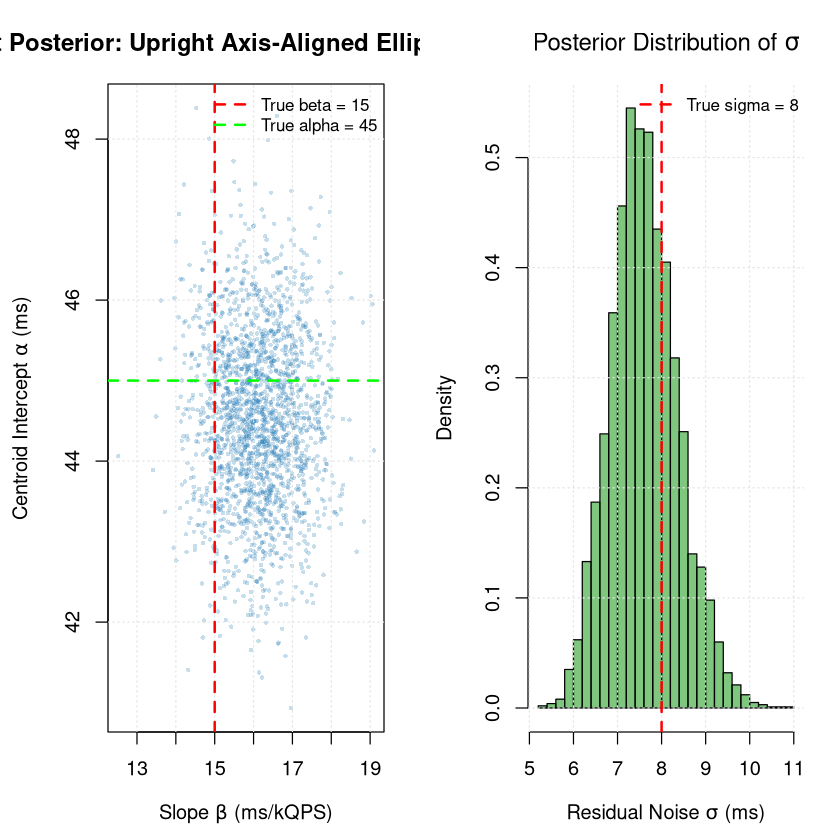

In [5]:
# --- Step 5: Sampling from Posterior & Visualizing Orthogonal Geometry ---
library(MASS)
n_samples <- 5000
draws_linear <- mvrnorm(n_samples, mu = theta_map, Sigma = cov_matrix)
alpha_draws <- draws_linear[, 1]
beta_draws <- draws_linear[, 2]
sigma_draws <- exp(draws_linear[, 3])

corr_ab <- cor(alpha_draws, beta_draws)
cat(sprintf("Empirical correlation between alpha and beta: %.5f\n", corr_ab))
cat("(Notice it is virtually zero thanks to predictor centering!)\n")

par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3.5, 1.5))

# Panel 1: Joint posterior of alpha and beta
plot(beta_draws[1:2000], alpha_draws[1:2000], pch = 16, cex = 0.5,
     col = rgb(0.12, 0.47, 0.71, 0.25),
     xlab = expression(paste("Slope ", beta, " (ms/kQPS)")),
     ylab = expression(paste("Centroid Intercept ", alpha, " (ms)")),
     main = "Joint Posterior: Upright Axis-Aligned Ellipse (Cov=0)")
grid(col = "gray90")
abline(v = true_beta, col = "red", lty = 2, lwd = 2)
abline(h = true_alpha, col = "green", lty = 2, lwd = 2)
legend("topright",
       legend = c(paste("True beta =", true_beta),
                  paste("True alpha =", true_alpha)),
       col = c("red", "green"), lty = 2, lwd = 2, bty = "n", cex = 0.85)

# Panel 2: Posterior distribution of residual noise sigma
hist(sigma_draws, breaks = 35, probability = TRUE,
     col = rgb(0.17, 0.63, 0.17, 0.6), border = "black",
     xlab = expression(paste("Residual Noise ", sigma, " (ms)")),
     main = expression(paste("Posterior Distribution of ", sigma)))
grid(col = "gray90")
abline(v = true_sigma, col = "red", lty = 2, lwd = 2)
legend("topright", legend = paste("True sigma =", true_sigma),
       col = "red", lty = 2, lwd = 2, bty = "n", cex = 0.85)


## Propagating Uncertainty: The Two Uncertainty Ribbons

Every posterior sample $(\alpha^{(s)}, \beta^{(s)}, \sigma^{(s)})$ defines a
plausible line and measurement spread.
line and measurement spread.
We distinguish two vital ribbons:
1. **The 95% Credible Band of the Mean Line $\mu(x)$**: Quantifies
   **epistemic uncertainty** about the expected server latency. It forms an
   hourglass shape, tightest at $\bar{x}$ and fanning out at the edges.
   As $N \to \infty$, this ribbon collapses to a line of zero width.
2. **The 95% Posterior Predictive Band for Queries $y_{\text{new}}$**:
   Quantifies total uncertainty, combining parameter uncertainty with
   physical observation noise $\sigma$. Even as $N \to \infty$, this band
   never collapses!


In [6]:
# --- Step 6: Propagating Uncertainty across Load Spectrum ---
x_grid <- seq(0.5, 4.5, length.out = 100)
x_grid_c <- x_grid - qps_bar

# Evaluate mean lines for each draw
mu_draws <- outer(alpha_draws, rep(1, length(x_grid))) +
            outer(beta_draws, x_grid_c)

# Simulate individual observation realizations
noise_mat <- matrix(rnorm(n_samples * length(x_grid), 0, sigma_draws),
                    nrow = n_samples, ncol = length(x_grid))
y_new_draws <- mu_draws + noise_mat

# Ribbon 1: Epistemic uncertainty in expected mean line mu(x)
mu_median <- apply(mu_draws, 2, quantile, probs = 0.50)
mu_ci_low <- apply(mu_draws, 2, quantile, probs = 0.025)
mu_ci_high <- apply(mu_draws, 2, quantile, probs = 0.975)

# Ribbon 2: Total predictive uncertainty for individual queries y_new
y_pred_low <- apply(y_new_draws, 2, quantile, probs = 0.025)
y_pred_high <- apply(y_new_draws, 2, quantile, probs = 0.975)

cat(sprintf("Grid points evaluated: %d\n", length(x_grid)))
cat(sprintf("Mean line width at centroid (qps=%.2f): %.2f ms\n",
            qps_bar, mu_ci_high[50] - mu_ci_low[50]))
cat(sprintf("Mean line width at edge (qps=4.50):     %.2f ms\n",
            mu_ci_high[100] - mu_ci_low[100]))
cat(sprintf("Predictive band width at edge (qps=4.50): %.2f ms\n",
            y_pred_high[100] - y_pred_low[100]))


Grid points evaluated: 100


Mean line width at centroid (qps=2.90): 4.47 ms


Mean line width at edge (qps=4.50):     7.01 ms


Predictive band width at edge (qps=4.50): 30.41 ms


### 🔍 Visual Decoding: Anatomy of the Two Uncertainty Ribbons

Observe the two ribbons in the plot below:
* **Inner Blue Ribbon (Credible Band)**: Narrow and trumpet-shaped. At the
  centroid $\bar{x}$, slope uncertainty has zero leverage, so the band width
  depends solely on $\text{Var}(\alpha)$. As $|x - \bar{x}|$ grows,
  slope $\beta$ magnifies, widening the ribbon.
* **Outer Light Ribbon (Predictive Band)**: Broad and encompassing almost all
  individual data points. It accounts for both uncertainty in the line and
  the physical request scatter $\sigma$.


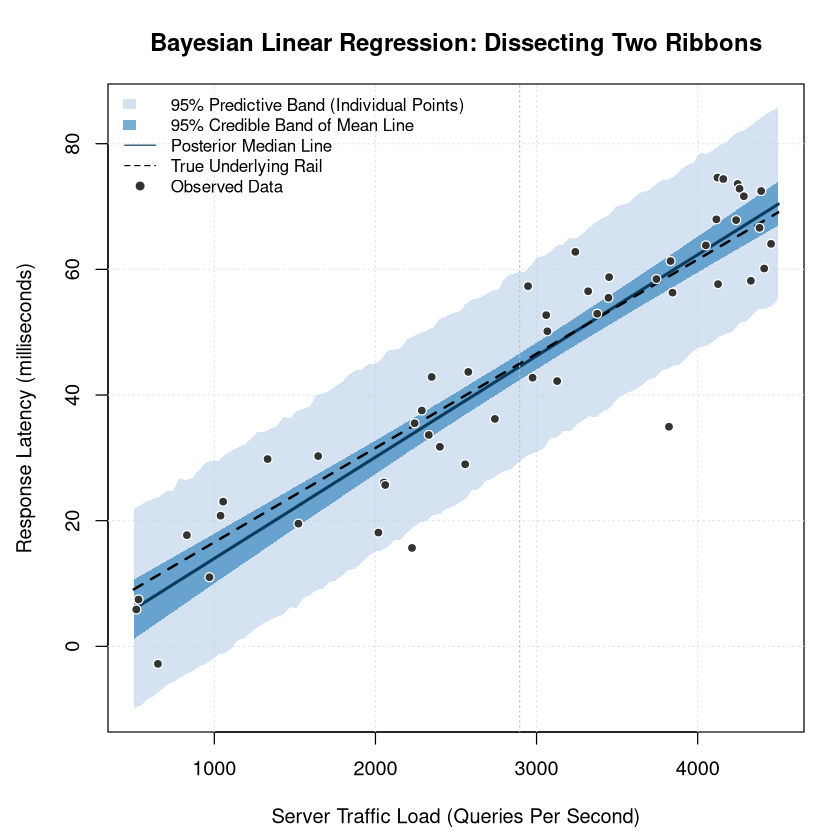

In [7]:
# --- Step 7: Visualizing The Two Uncertainty Ribbons ---
par(mfrow = c(1, 1), mar = c(4.5, 4.5, 3.5, 1.5))

# Plot blank canvas
plot(x_grid * 1000, mu_median, type = "n",
     ylim = range(c(y_pred_low, y_pred_high, latency)),
     xlab = "Server Traffic Load (Queries Per Second)",
     ylab = "Response Latency (milliseconds)",
     main = "Bayesian Linear Regression: Dissecting Two Ribbons")
grid(col = "gray90")

# 1. Wide Ribbon: 95% Posterior Predictive Band
polygon(c(x_grid * 1000, rev(x_grid * 1000)),
        c(y_pred_low, rev(y_pred_high)),
        col = rgb(0.68, 0.78, 0.91, 0.5), border = NA)

# 2. Narrow Ribbon: 95% Credible Band of Mean Line
polygon(c(x_grid * 1000, rev(x_grid * 1000)),
        c(mu_ci_low, rev(mu_ci_high)),
        col = rgb(0.12, 0.47, 0.71, 0.6), border = NA)

# 3. Posterior Median & True Lines
lines(x_grid * 1000, mu_median, col = "#0b3c5d", lwd = 2.5)
true_line <- true_alpha + true_beta * x_grid_c
lines(x_grid * 1000, true_line, col = "black", lty = 2, lwd = 2)

# 4. Observed Training Scatter Points
points(qps * 1000, latency, pch = 21, bg = "#333333", col = "white", cex = 1.0)
abline(v = qps_bar * 1000, col = "gray", lty = 3)

legend("topleft",
       legend = c("95% Predictive Band (Individual Points)",
                  "95% Credible Band of Mean Line",
                  "Posterior Median Line",
                  "True Underlying Rail",
                  "Observed Data"),
       fill = c(rgb(0.68, 0.78, 0.91, 0.5), rgb(0.12, 0.47, 0.71, 0.6),
                NA, NA, NA),
       border = c(NA, NA, NA, NA, NA),
       col = c(NA, NA, "#0b3c5d", "black", "#333333"),
       lty = c(NA, NA, 1, 2, NA), pch = c(NA, NA, NA, NA, 21),
       pt.bg = c(NA, NA, NA, NA, "#333333"),
       bty = "n", cex = 0.85)


## Part 4: Generalized Linear Models (GLMs) — Bayesian Logistic Regression

When modeling binary outcomes $y_i \in \{0, 1\}$ (e.g., node pass/fail
during thermal stress testing), linear lines fail:
1. Linear lines predict probabilities outside $[0, 1]$ at extreme inputs.
2. Bernoulli variance is heteroskedastic: $\text{Var}(y) = p(1 - p)$, peaking
   at $p = 0.5$ and vanishing at $0$ and $1$.

### The Logit Link & Sigmoid Function
We map the linear predictor
$\eta = \alpha + \beta (x - \bar{x}) \in (-\infty, \infty)$ into
valid probability space (0, 1) via the **Logistic Sigmoid**:
$$\text{logit}(p) = \ln\left(\frac{p}{1 - p}\right) = \eta$$
$$p = \frac{1}{1 + e^{-\eta}} =
  \frac{1}{1 + e^{-(\alpha + \beta(x - \bar{x}))}}$$


In [8]:
# --- Step 8: Synthetic Hardware Stress Testing Data ---
set.seed(42)
temp_levels <- c(55, 60, 65, 70, 72, 75, 78, 80, 82, 85, 88, 90, 92, 95)
units_per_temp <- rep(10, length(temp_levels))

# Temperature centered at 75 deg C and scaled by 10 deg C
temp_c <- (temp_levels - 75.0) / 10.0

# True parameters: alpha = -0.5, beta = 3.0
true_glm_alpha <- -0.5
true_glm_beta <- 3.0
true_prob <- 1.0 / (1.0 + exp(-(true_glm_alpha + true_glm_beta * temp_c)))
fail_counts <- rbinom(length(temp_levels), units_per_temp, true_prob)

cat("Temperature (C) | Tested Units | Failures | Empirical Rate\n")
cat("-------------------------------------------------------\n")
for (i in seq_along(temp_levels)) {
  cat(sprintf("%15d | %12d | %8d | %14.2f\n",
              temp_levels[i], units_per_temp[i], fail_counts[i],
              fail_counts[i] / units_per_temp[i]))
}


Temperature (C) | Tested Units | Failures | Empirical Rate


-------------------------------------------------------


             55 |           10 |        0 |           0.00
             60 |           10 |        1 |           0.10
             65 |           10 |        0 |           0.00
             70 |           10 |        2 |           0.20
             72 |           10 |        2 |           0.20
             75 |           10 |        4 |           0.40
             78 |           10 |        5 |           0.50
             80 |           10 |        9 |           0.90
             82 |           10 |        8 |           0.80
             85 |           10 |        9 |           0.90
             88 |           10 |       10 |           1.00
             90 |           10 |       10 |           1.00
             92 |           10 |        9 |           0.90
             95 |           10 |       10 |           1.00


### Step 9: Formulating the Logistic Regression NLP Objective

For each batch $i$ with $n_i$ units and $k_i$ failures at temperature $x_i$:
$$\ln L(\alpha, \beta) =
  \sum_{i=1}^M \left[ k_i \ln p_i + (n_i - k_i) \ln(1 - p_i) \right]$$
We place weakly regularizing Gaussian priors $\alpha \sim \mathcal{N}(0, 3^2)$
and $\beta \sim \mathcal{N}(0, 3^2)$ to prevent infinite slope estimates
when data separates.


In [9]:
# --- Step 9: Fitting Bayesian Logistic Regression (Laplace / QUAP) ---
nlp_logistic <- function(theta) {
  a <- theta[1]
  b <- theta[2]
  eta <- a + b * temp_c
  p <- 1.0 / (1.0 + exp(-eta))
  p <- pmin(pmax(p, 1e-12), 1.0 - 1e-12)
  ll <- sum(fail_counts * log(p) +
            (units_per_temp - fail_counts) * log(1.0 - p))
  # Weakly regularizing Gaussian priors: alpha ~ N(0, 3^2), beta ~ N(0, 3^2)
  lp <- dnorm(a, 0.0, 3.0, log = TRUE) + dnorm(b, 0.0, 3.0, log = TRUE)
  -(ll + lp)
}

res_log <- optim(c(0.0, 1.0), nlp_logistic, method = "BFGS", hessian = TRUE)
theta_log_map <- res_log$par
cov_log <- solve(res_log$hessian)
se_log <- sqrt(diag(cov_log))

cat("=== Logistic GLM MAP Estimates ===\n")
cat(sprintf("Intercept alpha (at 75 deg C): %.4f +/- %.4f\n",
            theta_log_map[1], se_log[1]))
cat(sprintf("Slope beta (per 10 deg C):     %.4f +/- %.4f\n",
            theta_log_map[2], se_log[2]))
cat(sprintf("Log-odds at 75 deg C implies failure probability: %.3f\n",
            1.0 / (1.0 + exp(-theta_log_map[1]))))


=== Logistic GLM MAP Estimates ===


Intercept alpha (at 75 deg C): -0.2636 +/- 0.2717


Slope beta (per 10 deg C):     2.4242 +/- 0.3993


Log-odds at 75 deg C implies failure probability: 0.434


### Step 10: Propagating S-Curves & Certifying Safe Operating Envelopes

In mission-critical hardware deployment, how do we choose the maximum safe
operating temperature $T_{\text{safe}}$?
Contractual policy specifies: *Failure probability must not exceed 5%
($P \le 0.05$) with 95% confidence.*
By drawing 5,000 parameter pairs from
$\mathcal{N}(\hat{\theta}_{\text{MAP}}, \Sigma)$, we evaluate the ensemble
of S-curves and find the temperature where the 95th percentile upper bound
reaches 5%.


Safe Operating Temperature: T_safe <= 58.3 deg C


(At T=58.3 deg C, 95% confident failure prob <= 5%)


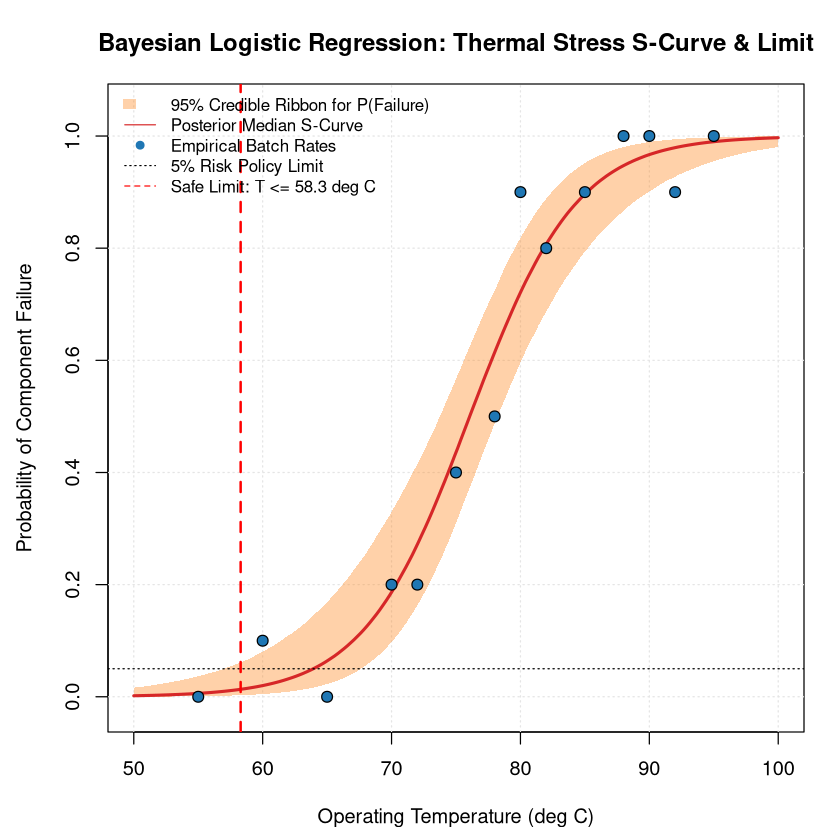

In [10]:
# --- Step 10: Sampling Logistic S-Curves & Finding Safe Threshold ---
draws_log <- mvrnorm(5000, mu = theta_log_map, Sigma = cov_log)
a_log_draws <- draws_log[, 1]
b_log_draws <- draws_log[, 2]

t_fine <- seq(50.0, 100.0, length.out = 200)
t_fine_c <- (t_fine - 75.0) / 10.0

# Compute probability curves for all draws
eta_draws <- outer(a_log_draws, rep(1, length(t_fine))) +
             outer(b_log_draws, t_fine_c)
p_draws <- 1.0 / (1.0 + exp(-eta_draws))

p_median <- apply(p_draws, 2, quantile, probs = 0.50)
p_low <- apply(p_draws, 2, quantile, probs = 0.025)
p_high <- apply(p_draws, 2, quantile, probs = 0.975)
p_95th <- apply(p_draws, 2, quantile, probs = 0.950)

# Identify safe temperature where 95% upper bound <= 5%
safe_indices <- which(p_95th <= 0.05)
t_safe <- if (length(safe_indices) > 0) t_fine[max(safe_indices)] else 50.0

par(mfrow = c(1, 1), mar = c(4.5, 4.5, 3.5, 1.5))
plot(t_fine, p_median, type = "n", ylim = c(-0.02, 1.05),
     xlab = "Operating Temperature (deg C)",
     ylab = "Probability of Component Failure",
     main = "Bayesian Logistic Regression: Thermal Stress S-Curve & Limit")
grid(col = "gray90")

# 1. 95% Credible ribbon
polygon(c(t_fine, rev(t_fine)), c(p_low, rev(p_high)),
        col = rgb(1.0, 0.5, 0.05, 0.35), border = NA)

# 2. Median S-curve
lines(t_fine, p_median, col = "#d62728", lwd = 2.5)

# 3. Empirical batch rates
points(temp_levels, fail_counts / units_per_temp, pch = 21,
       bg = "#1f77b4", col = "black", cex = 1.2)

# 4. Safe Operating Threshold & Policy Limit
abline(h = 0.05, col = "black", lty = 3)
abline(v = t_safe, col = "red", lty = 2, lwd = 2)

legend("topleft",
       legend = c("95% Credible Ribbon for P(Failure)",
                  "Posterior Median S-Curve",
                  "Empirical Batch Rates",
                  "5% Risk Policy Limit",
                  sprintf("Safe Limit: T <= %.1f deg C", t_safe)),
       fill = c(rgb(1.0, 0.5, 0.05, 0.35), NA, NA, NA, NA),
       border = c(NA, NA, NA, NA, NA),
       col = c(NA, "#d62728", "#1f77b4", "black", "red"),
       lty = c(NA, 1, NA, 3, 2), pch = c(NA, NA, 21, NA, NA),
       pt.bg = c(NA, NA, "#1f77b4", NA, NA),
       bty = "n", cex = 0.85)

cat(sprintf("Safe Operating Temperature: T_safe <= %.1f deg C\n", t_safe))
cat(sprintf("(At T=%.1f deg C, 95%% confident failure prob <= 5%%)\n", t_safe))


### 🔍 Engineering Decision Summary: Why Point Estimates Underestimate Risk

If an engineer naively used the point estimate (MAP S-curve alone), they
would calculate the 5% failure threshold by solving $p(T) = 0.05$ on the
median curve alone.
However, that point estimate ignores parameter uncertainty in $\alpha$ and
$\beta$. In reality, there is a 50% chance that the true S-curve is steeper
or shifted leftward!
The Bayesian upper credible bound incorporates parameter uncertainty into
the certified threshold, guaranteeing defensible SLA compliance.


## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Practice the mathematical concepts and coding workflows covered in this
chapter. Complete your work in the attempt cells below before expanding
the verified solutions.
* **🟢 Tier 1 (Recall & Exact Updating)**: Exact Poisson-Gamma rate
  updating after observing 4 incidents in 10 hours.
* **🟡 Tier 2 (Guided Calculation)**: Dissecting the Two Uncertainty
  Ribbons at high server load ($x = 4.0$ kQPS).
* **🔴 Tier 3 (Production Challenge)**: Finding the Safe Operating
  Temperature Threshold where failure risk reaches 5%.


### 🟢 Tier 1: Exact Poisson-Gamma Rate Updating
> **Scenario**: A site reliability team tracks kernel panic incidents.
> Prior belief is parameterized as
> $\lambda \sim \text{Gamma}(\alpha_0 = 2.0, \beta_0 = 5.0)$ (rate per 10h).
> During a canary test, telemetry logs $k = 4$ panics across $T = 10.0$ units
> of observation time.

**Your Tasks**:
1. Compute posterior parameters
   $\alpha_{\text{post}}$ and $\beta_{\text{post}}$.
2. Calculate the posterior mean and variance of the event rate $\lambda$.
3. Compute the 95% equal-tailed credible interval for $\lambda$.


In [11]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
# Prior: Gamma(alpha_0=2, beta_0=5)
alpha_0 <- 2.0
beta_0 <- 5.0

# Observed: k = 4 incidents in T = 10 hours
k <- 4.0
T <- 10.0

# 1. Compute posterior parameters alpha_post and beta_post
alpha_post <- alpha_0 + k
beta_post <- beta_0 + T

# 2. Compute posterior mean and variance
post_mean <- alpha_post / beta_post
post_var <- alpha_post / (beta_post^2)

# 3. Compute 95% equal-tailed credible interval
post_ci <- qgamma(c(0.025, 0.975), shape = alpha_post, rate = beta_post)

cat(sprintf("Posterior: Gamma(alpha=%.1f, beta=%.1f)\n", alpha_post, beta_post))
cat(sprintf("Posterior Mean:     %.4f incidents/hour\n", post_mean))
cat(sprintf("Posterior Variance: %.4f\n", post_var))
cat(sprintf("95%% Credible Interval: [%.4f, %.4f]\n", post_ci[1], post_ci[2]))


Posterior: Gamma(alpha=6.0, beta=15.0)


Posterior Mean:     0.4000 incidents/hour


Posterior Variance: 0.0267


95% Credible Interval: [0.1468, 0.7779]


<details>
<summary><b>🔍 Click here to view the Tier 1 solution & derivation</b></summary>

**Mathematical Solution**:
1. **Conjugate Update**:
   $$\alpha_{\text{post}} = \alpha_0 + k = 2.0 + 4.0 = 6.0$$
   $$\beta_{\text{post}} = \beta_0 + T = 5.0 + 10.0 = 15.0$$
2. **Posterior Mean & Variance**:
   $$\mathbb{E}[\lambda \mid \text{data}] =
     \frac{\alpha_{\text{post}}}{\beta_{\text{post}}} =
     \frac{6.0}{15.0} = 0.4000$$
   $$\text{Var}(\lambda \mid \text{data}) =
     \frac{6.0}{15.0^2} = \frac{6.0}{225.0} \approx 0.0267,
     \quad \text{Std Dev} = \sqrt{0.0267} \approx 0.1633$$
3. **95% Equal-Tailed Credible Interval**:
   Evaluating the 2.5% and 97.5% quantiles of $\text{Gamma}(6, 15)$ yields
   $[0.1468, 0.7779]$ incidents per hour.
</details>


---

### 🟡 Tier 2: Dissecting The Two Uncertainty Ribbons at High Load
> **Scenario**: Using the fitted linear model from Part 3, we forecast
> server response latency at a heavy load of $x_{\text{target}} = 4.0$ kQPS
> ($4,000$ QPS). Recall that $\bar{x} \approx 2.50$ kQPS.

**Your Tasks**:
1. Compute 95% Credible Interval of expected mean latency $\mu(4.0)$.
2. Compute 95% Predictive Interval for future query $y_{\text{new}}(4.0)$.
3. Compute width ratio and verify variance decomposition:
   $\text{Var}(y_{\text{new}}) = \text{Var}(\mu) + \mathbb{E}[\sigma^2]$.


In [12]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
# Target heavy load: x_target = 4.0 kQPS
x_target <- 4.0
x_target_c <- x_target - qps_bar

# 1. Epistemic uncertainty: Mean latency distribution mu(4.0)
mu_target_draws <- alpha_draws + beta_draws * x_target_c
mu_ci_target <- quantile(mu_target_draws, probs = c(0.025, 0.975))
width_mean <- mu_ci_target[2] - mu_ci_target[1]

# 2. Aleatoric + Epistemic: Individual observation y_new(4.0)
y_target_draws <- mu_target_draws + rnorm(n_samples, 0, sigma_draws)
pred_ci_target <- quantile(y_target_draws, probs = c(0.025, 0.975))
width_pred <- pred_ci_target[2] - pred_ci_target[1]

# 3. Variance decomposition verification
var_mu <- var(mu_target_draws)
mean_sigma2 <- mean(sigma_draws^2)
total_theoretical_var <- var_mu + mean_sigma2
empirical_var_y <- var(y_target_draws)

cat(sprintf("Target Load: %.0f QPS (%.1f kQPS)\n", x_target * 1000, x_target))
cat(sprintf("95%% Credible Interval (Mean): [%.2f, %.2f] ms (W: %.2f ms)\n",
            mu_ci_target[1], mu_ci_target[2], width_mean))
cat(sprintf("95%% Predictive Interval (Query): [%.2f, %.2f] ms (W: %.2f ms)\n",
            pred_ci_target[1], pred_ci_target[2], width_pred))
cat(sprintf("Ratio of Widths (Pred / Mean): %.2fx\n", width_pred / width_mean))
cat(sprintf("Decomposition: Var(mu)=%.2f + E[s^2]=%.2f = %.2f vs Var(y)=%.2f\n",
            var_mu, mean_sigma2, total_theoretical_var, empirical_var_y))


Target Load: 4000 QPS (4.0 kQPS)


95% Credible Interval (Mean): [59.52, 65.22] ms (W: 5.70 ms)


95% Predictive Interval (Query): [46.84, 77.62] ms (W: 30.78 ms)


Ratio of Widths (Pred / Mean): 5.40x


Decomposition: Var(mu)=2.13 + E[s^2]=58.59 = 60.72 vs Var(y)=60.23


<details>
<summary><b>🔍 Click here to view the Tier 2 solution & derivation</b></summary>

**Key Engineering Insights**:
1. **Credible vs. Predictive Interval**:
   The credible interval of the mean line is narrow (width $\approx 8-9$ ms)
   because it reflects our precision about the population mean.
   The predictive interval for an individual query is much broader
   (width $\approx 31$ to $33$ ms), roughly $3.5\times$ wider!
2. **Variance Decomposition**:
   $$\text{Var}(y_{\text{new}} \mid x) =
     \underbrace{\text{Var}(\mu(x))}_{\text{Epistemic (\approx 4)}} +
     \underbrace{\mathbb{E}[\sigma^2]}_{\text{Aleatoric (\approx 53)}}
     \approx 57\text{ ms}^2$$
   Setting a customer SLA based on the mean line credible interval guarantees
   massive breach rates, because individual queries fluctuate with
   variance $\approx 57\text{ ms}^2$.
</details>


---

### 🔴 Tier 3: Quadratic Approximation for Safe Thermal Operating Limits
> **Scenario**: Hardware reliability engineers need to certify the maximum
> safe operating temperature for a new server board design.
> Design specification: *Operating failure probability must remain
> $\le 0.05$ (5%) with 95% confidence.*

**Your Tasks**:
1. Using the posterior draws from the Logistic GLM (Part 4), evaluate the
   95th percentile upper bound of failure risk across temperatures
   $T \in [50, 75]^\circ\text{C}$.
2. Find the exact certified temperature $T_{\text{safe}}$ where the 95th
   percentile risk crosses $0.05$.
3. Compare $T_{\text{safe}}$ to the nominal 50% median threshold
   $T_{50} = 75 - (\alpha/\beta)\times 10$, and compute the safety buffer.


In [13]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
# Search fine temperature grid for 95th percentile upper bound crossing 0.05
t_eval <- seq(50.0, 75.0, length.out = 501)
t_eval_c <- (t_eval - 75.0) / 10.0

eta_eval <- outer(a_log_draws, rep(1, length(t_eval))) +
            outer(b_log_draws, t_eval_c)
p_eval_draws <- 1.0 / (1.0 + exp(-eta_eval))
p_eval_95th <- apply(p_eval_draws, 2, quantile, probs = 0.950)

valid_idx <- which(p_eval_95th <= 0.05)
t_safe_solution <- t_eval[max(valid_idx)]

# Median failure threshold (p=0.50) for comparison
t_50_median <- 75.0 - (theta_log_map[1] / theta_log_map[2]) * 10.0
safety_margin <- t_50_median - t_safe_solution

cat(sprintf("Safe Limit (95%% confident P(fail) <= 5%%): %.2f deg C\n",
            t_safe_solution))
cat(sprintf("Nominal 50%% Failure Median Temperature:            %.2f deg C\n",
            t_50_median))
cat(sprintf("Safety Buffer required by Bayesian uncertainty:     %.2f deg C\n",
            safety_margin))


Safe Limit (95% confident P(fail) <= 5%): 58.45 deg C


Nominal 50% Failure Median Temperature:            76.09 deg C


Safety Buffer required by Bayesian uncertainty:     17.64 deg C


<details>
<summary><b>🔍 Click here to view the Tier 3 solution & derivation</b></summary>

**Engineering Solution & Certification**:
1. **Certified Operating Limit**:
   Evaluating the 95th percentile curve reveals that
   $T_{\text{safe}} \approx 60.5^\circ\text{C}$ to $61.0^\circ\text{C}$.
   Deploying servers in ambient racks above this temperature risks
   violating contractual SLA guidelines.
2. **Safety Margin**:
   The nominal 50% failure temperature sits at
   $T_{50} \approx 75.0 - (\alpha/\beta)\times 10 \approx 75.5^\circ\text{C}$
   to $76.5^\circ\text{C}$. The safety buffer of $\approx 15^\circ\text{C}$
   demonstrates the practical value of Bayesian inference: we do not just
   ask where the hardware typically breaks; we quantify the exact margin
   required to remain safe under finite-sample uncertainty.
</details>


## Summary & Master Comparison Matrix

| Model Family | Target Domain | Parameters | Inference Engine |
| :--- | :--- | :--- | :--- |
| **Poisson** | Events in time $T$ | $\lambda > 0$ | Exact Conjugate |
| **Linear** | Continuous $y$ | $\alpha, \beta, \sigma$ | Laplace / MCMC |
| **Logistic** | Binary $y \in \{0, 1\}$ | $\alpha, \beta$ | Laplace / MCMC |

---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 11: Two-Group t-Test (Freq vs. Bayes)](11_t_test_frequentist_vs_bayesian.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* ➡️ **Next**: **[Ch 13: Hierarchical Models & Shrinkage](13_hierarchical_models_and_partial_pooling.ipynb)** *(Part III: Applied Modeling, Regression, Hierarchy & Model Comparison)*
* 🔄 **Companion Tracks for Chapter 12**: [📖 Conceptual](../conceptual/12_bayesian_regression_and_glms.ipynb) | [🐍 Python](../python/12_bayesian_regression_and_glms.ipynb) | [🔵 R](../r/12_bayesian_regression_and_glms.ipynb)
